# 03 — Comparación de 8, 16 y 32 frames por clip

El plan fija **16 frames** por clip. Antes de darlo por bueno se compara contra
8 y 32 con lo que se puede **medir sin entrenar**, sobre **Real Life** y **RWF-2000**:

| Medida | Qué responde |
|---|---|
| Separación temporal entre frames | ¿Cuánto movimiento queda "entre" dos frames que el modelo no ve? |
| Distancia al pico de movimiento | ¿Qué tan cerca cae un frame muestreado del momento de más acción? |
| Redundancia | ¿Los frames vecinos son casi iguales (se desperdicia cómputo)? |
| Costo | Tiempo de extracción, memoria del tensor y tiempo de MobileNetV2 por clip. |

**Límite importante:** nada de esto mide la *exactitud* del modelo. Saber si
8, 16 o 32 clasifica mejor requiere entrenar con cada valor (fase de
entrenamiento); aquí solo se reúne la evidencia de costo y cobertura.

Se usa `extract_frames` de `src/preprocessing/video_pipeline.py`, el mismo
código que usará el entrenamiento. **Requiere haber ejecutado antes el notebook 02**
(genera los CSV de metadatos en `data/processed/`).

## 1. Imports y muestra de videos

In [1]:
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.models import mobilenet_v2

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.preprocessing.video_pipeline import extract_frames, resize_and_convert

COLORES = {"violencia": "#d1495b", "no_violencia": "#2e86ab"}
VALORES_T = (8, 16, 32)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

# Metadatos generados por 02_eda_datasets.ipynb (data/processed no se versiona).
partes = []
for nombre in ("real_life", "rwf2000"):
    csv = ROOT / "data" / "processed" / f"metadata_{nombre}.csv"
    if csv.exists():
        partes.append(pd.read_csv(csv, keep_default_na=False))
    else:
        print(f"[{nombre}] sin metadatos ({csv.name}): ejecutar antes el notebook 02")
meta = pd.concat(partes, ignore_index=True)

# Se usan clips de hasta 30 s: el perfil de movimiento exige decodificar el
# video completo y los de varios minutos tardarian demasiado (son 3 de 4000;
# se tratan aparte, ver notebook 02).
POR_CLASE = 40
muestra = (meta[meta["segundos"] <= 30]
           .groupby(["dataset", "clase"], group_keys=False)
           .sample(POR_CLASE, random_state=42)
           .reset_index(drop=True))
DATASETS = list(muestra["dataset"].unique())
print(muestra.groupby(["dataset", "clase"]).size().to_string())

dataset    clase       
real_life  no_violencia    40
           violencia       40
rwf2000    no_violencia    40
           violencia       40


## 2. Perfil de movimiento de cada video

Para cada video se decodifican **todos** los frames (en gris y a 64×64, por
velocidad) y se calcula la diferencia media entre frames consecutivos. Esa
curva es la "cantidad de movimiento" en el tiempo; su máximo (suavizado ~0,5 s)
es el momento de mayor acción, que es el que un buen muestreo no debería perder.

In [2]:
def perfil_movimiento(ruta: str) -> tuple[np.ndarray, float]:
    """Devuelve (movimiento por frame, fps) leyendo el video completo.

    El movimiento del frame i es la diferencia absoluta media entre el
    frame i y el i-1 (el primero vale 0), en escala de grises 64x64.
    """
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    previo, mov = None, []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        g = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (64, 64),
                       interpolation=cv2.INTER_AREA).astype(np.float32)
        mov.append(0.0 if previo is None else float(np.abs(g - previo).mean()))
        previo = g
    cap.release()
    return np.array(mov), fps


def indices_muestreados(total: int, n: int) -> np.ndarray:
    """Mismos indices que usa extract_frames (np.linspace con enteros)."""
    return np.linspace(0, total - 1, n, dtype=int)


perfiles = {}
t0 = time.time()
for _, v in muestra.iterrows():
    perfiles[v["ruta"]] = perfil_movimiento(v["ruta"])
print(f"{len(perfiles)} perfiles en {time.time() - t0:.0f} s")

160 perfiles en 43 s


## 3. Medidas por video y por valor de T

- **Separación**: segundos entre dos frames muestreados consecutivos
  (duración real del clip dividida por T − 1).
- **Distancia al pico**: segundos entre el frame de mayor movimiento
  (suavizado) y el frame muestreado más cercano.
- **Redundancia**: diferencia media entre frames muestreados vecinos,
  en gris 64×64 (más baja = frames más parecidos entre sí).

In [3]:
def suavizar(x: np.ndarray, ventana: int) -> np.ndarray:
    """Media movil simple; evita que un solo frame ruidoso sea 'el pico'."""
    ventana = max(1, ventana)
    return np.convolve(x, np.ones(ventana) / ventana, mode="same")


filas = []
for _, v in muestra.iterrows():
    mov, fps = perfiles[v["ruta"]]
    total = len(mov)  # frames realmente decodificados (mas fiable que el header)
    pico = int(np.argmax(suavizar(mov, int(round(fps * 0.5)))))
    for n in VALORES_T:
        idx = indices_muestreados(total, n)
        filas.append({
            "dataset": v["dataset"], "clase": v["clase"], "ruta": v["ruta"], "T": n,
            "separacion_s": (total / fps) / (n - 1),
            "dist_pico_s": float(np.abs(idx - pico).min() / fps),
        })
res = pd.DataFrame(filas)

# Redundancia y tiempo de extraccion usando el extractor real del proyecto.
red, tiempos = [], []
for _, v in muestra.iterrows():
    for n in VALORES_T:
        t0 = time.perf_counter()
        frames = extract_frames(v["ruta"], n)
        tiempos.append(time.perf_counter() - t0)
        g = np.array([cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), (64, 64),
                                 interpolation=cv2.INTER_AREA) for f in frames],
                     dtype=np.float32)
        red.append(float(np.abs(np.diff(g, axis=0)).mean()))
res["redundancia"] = red
res["extraccion_ms"] = np.array(tiempos) * 1000

tabla = res.groupby(["dataset", "T"])[["separacion_s", "dist_pico_s", "redundancia", "extraccion_ms"]].agg(
    ["mean", "median"]).round(3)
print(tabla.to_string())

             separacion_s        dist_pico_s        redundancia         extraccion_ms         
                     mean median        mean median        mean  median          mean   median
dataset   T                                                                                   
real_life 8         0.702  0.714       0.195  0.204      27.101  24.580       100.157   52.668
          16        0.328  0.333       0.079  0.080      20.481  18.043       186.530   92.299
          32        0.159  0.161       0.039  0.037      14.834  12.419       363.691  177.161
rwf2000   8         0.714  0.714       0.207  0.233       7.595   5.167       109.058   59.412
          16        0.333  0.333       0.069  0.067       5.176   3.750       215.630  111.687
          32        0.161  0.161       0.041  0.033       3.384   2.393       431.624  227.752


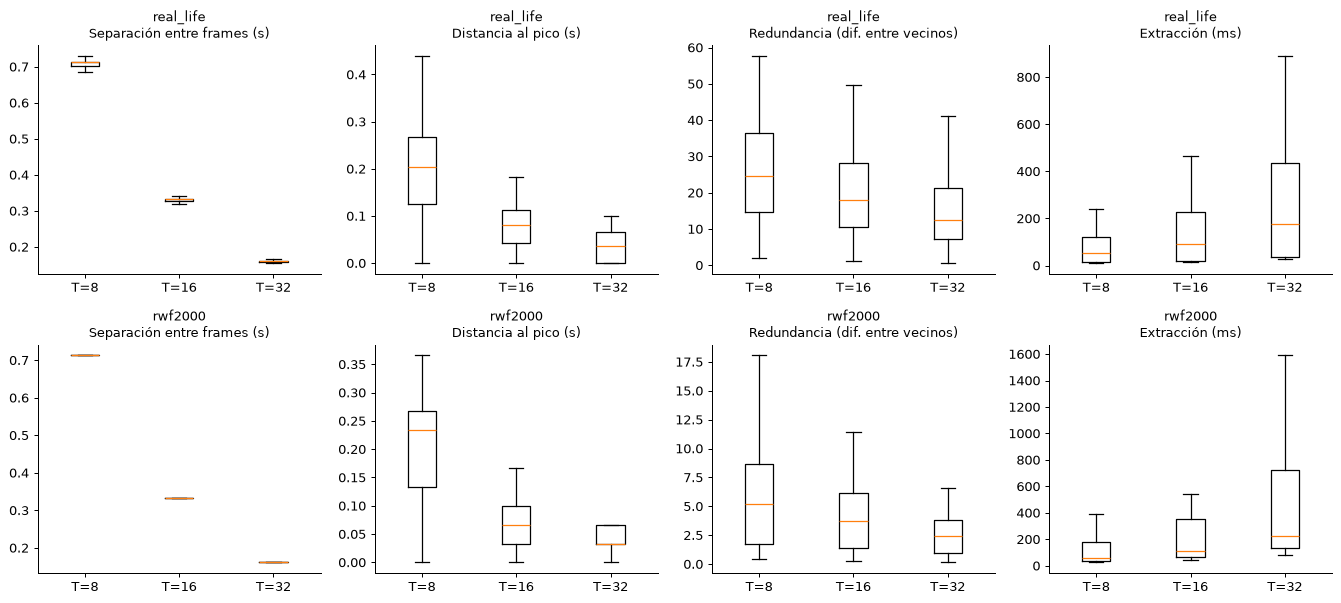

In [4]:
fig, ejes = plt.subplots(len(DATASETS), 4, figsize=(15, 3.4 * len(DATASETS)), squeeze=False)
for fila, ds in enumerate(DATASETS):
    d = res[res["dataset"] == ds]
    for ax, col, titulo in zip(
            ejes[fila],
            ["separacion_s", "dist_pico_s", "redundancia", "extraccion_ms"],
            ["Separación entre frames (s)", "Distancia al pico (s)",
             "Redundancia (dif. entre vecinos)", "Extracción (ms)"]):
        ax.boxplot([d.loc[d["T"] == n, col] for n in VALORES_T],
                   tick_labels=[f"T={n}" for n in VALORES_T], showfliers=False)
        ax.set_title(f"{ds}\n{titulo}", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Costo de cómputo: MobileNetV2 con T frames

El extractor por frame de la arquitectura candidata es MobileNetV2; su costo
crece con T (aquí más que proporcionalmente). Se mide el tiempo real del *forward* de un clip en
CPU. Los pesos no afectan la latencia, así que se usa `weights=None` (sin
descargar nada). Es CPU de esta máquina, no la de la demo final, y no depende
del dataset.

In [5]:
backbone = mobilenet_v2(weights=None).features.eval()

costo = []
with torch.no_grad():
    for n in VALORES_T:
        clip = torch.randn(n, 3, 224, 224)  # un clip: T frames como batch
        backbone(clip)  # calentamiento
        tiempos_fw = []
        for _ in range(5):
            t0 = time.perf_counter()
            backbone(clip)
            tiempos_fw.append(time.perf_counter() - t0)
        costo.append({
            "T": n,
            "forward_ms_por_clip": round(float(np.median(tiempos_fw)) * 1000, 1),
            "tensor_MB_por_clip": round(n * 3 * 224 * 224 * 4 / 1e6, 1),
            "tensor_MB_batch8": round(8 * n * 3 * 224 * 224 * 4 / 1e6, 1),
        })
costo = pd.DataFrame(costo)
print(costo.to_string(index=False))

 T  forward_ms_por_clip  tensor_MB_por_clip  tensor_MB_batch8
 8                 71.8                 4.8              38.5
16                168.5                 9.6              77.1
32                415.2                19.3             154.1


## 5. Comparación visual

Un clip de `violencia` de cada dataset representado con 8, 16 y 32 frames (ya a
224×224 como los vería el modelo). Debajo, el perfil de movimiento y los
instantes muestreados.

real_life -> V_827.mp4 (4.8 s, 30 fps)


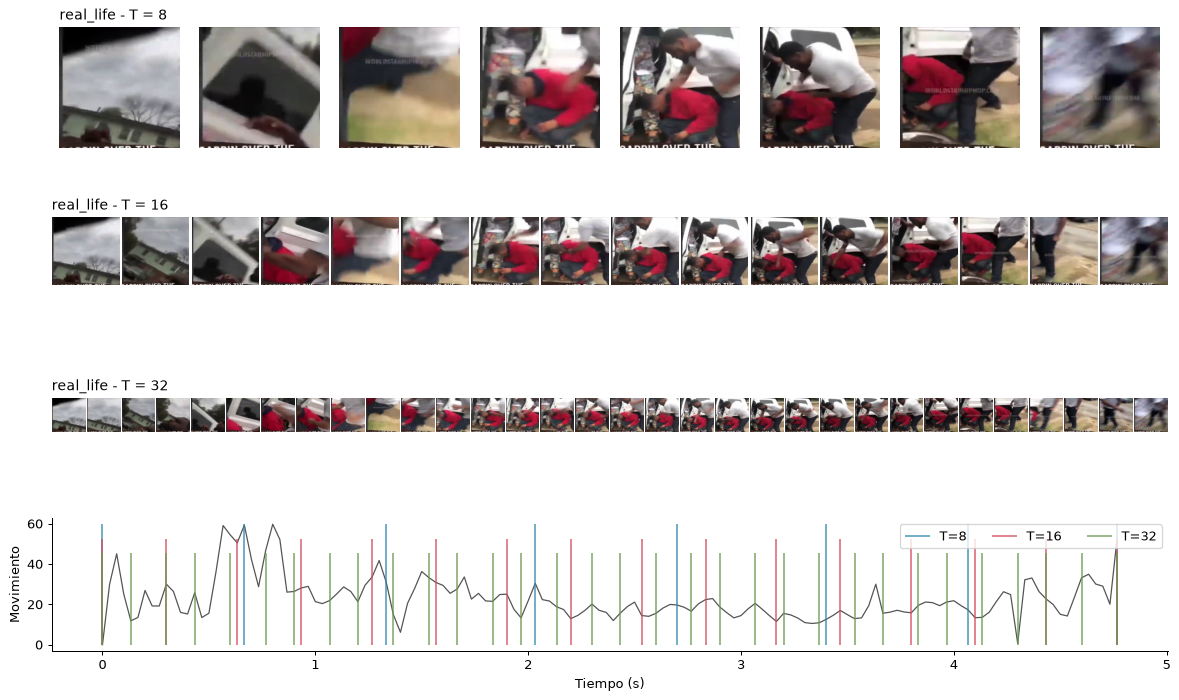

rwf2000 -> g6jdqkcdgqk_3.avi (5.0 s, 30 fps)


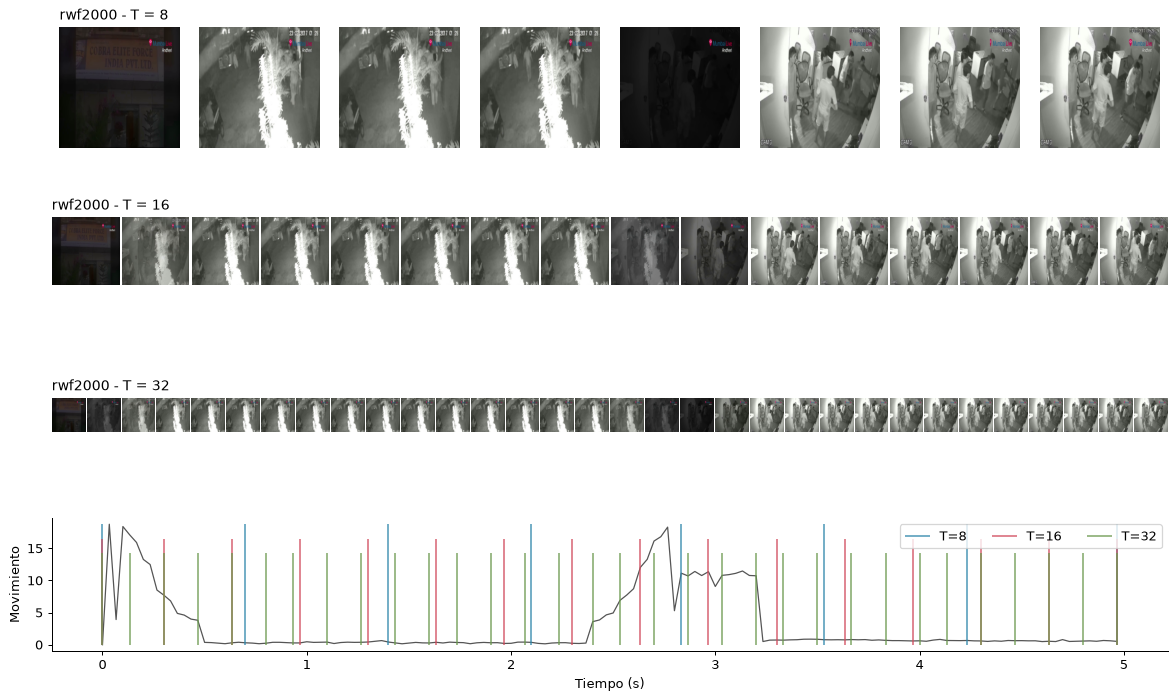

In [6]:
def figura_clip(ruta: str, titulo: str) -> None:
    """Dibuja el clip con T=8/16/32 y el perfil de movimiento debajo."""
    mov, fps = perfiles[ruta]
    print(titulo, "->", Path(ruta).name, f"({len(mov) / fps:.1f} s, {fps:.0f} fps)")
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(4, 1, height_ratios=[1, 1, 1, 1.1], hspace=0.35)
    for fila, n in enumerate(VALORES_T):
        sub = gs[fila].subgridspec(1, n, wspace=0.03)
        frames = resize_and_convert(extract_frames(ruta, n), 224)  # RGB 224x224
        for j in range(n):
            ax = fig.add_subplot(sub[0, j])
            ax.imshow(frames[j])
            ax.axis("off")
            if j == 0:
                ax.set_title(f"{titulo} - T = {n}", loc="left", fontsize=11)
    ax = fig.add_subplot(gs[3])
    ax.plot(np.arange(len(mov)) / fps, mov, color="#555", lw=1)
    for n, c, dy in zip(VALORES_T, ["#2e86ab", "#d1495b", "#6a994e"], (0, 1, 2)):
        idx = indices_muestreados(len(mov), n)
        ax.vlines(idx / fps, 0, mov.max() * (1 - 0.12 * dy), color=c, alpha=0.7, label=f"T={n}")
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Movimiento")
    ax.legend(ncol=3, loc="upper right")
    plt.show()


# Clip de violencia con mas movimiento sostenido (percentil 90). Con el maximo
# se elegian clips con cortes de escena, cuyo salto brusco parece "movimiento".
for ds in DATASETS:
    cand = muestra[(muestra["dataset"] == ds) & (muestra["clase"] == "violencia")]
    elegido = max(cand["ruta"], key=lambda r: np.percentile(perfiles[r][0], 90))
    figura_clip(elegido, ds)

## 6. Conclusiones

Medido sobre 160 clips (40 por clase y dataset, ≤ 30 s), en la CPU de esta
máquina. Los tiempos varían bastante entre ejecuciones (entre ~±10 % y ~±15 %
en el forward), por eso se dan como rango.

| T | Separación media | Forward MobileNetV2 por clip | Tensor de entrada, batch de 8 | Extracción, mediana (Real Life / RWF) |
|---|---|---|---|---|
| 8 | 0,70–0,71 s | ≈ 70–85 ms | 38,5 MB | ≈ 51 / 58 ms |
| 16 | 0,33 s | ≈ 170–200 ms | 77,1 MB | ≈ 93 / 112 ms |
| 32 | 0,16 s | ≈ 410–480 ms | 154,1 MB | ≈ 177 / 222 ms |

- **Costo:** pasar de 16 a 32 frames multiplica por ~2,5 el tiempo del extractor de
  MobileNetV2 (2,46 veces en la medición: 168,5 → 415,2 ms) y duplica la memoria del batch. Pasar de 16 a 8 lo reduce a ~35–45 %.
- **Cobertura:** con 8 frames queda ~0,7 s entre muestras. Un empujón o un
  arrebato de menos de un segundo podría caer entre dos frames y no verse (esto es
  una inferencia a partir de la separación, **no** algo medido con el modelo). Con
  16 la separación baja a ~0,33 s y con 32 a ~0,16 s. Es igual en ambos datasets
  porque casi todos los clips duran 5 s.
- **Redundancia (diferencia media entre frames vecinos):** baja al subir T en
  ambos datasets (Real Life 27 → 20 → 15; RWF-2000 7,6 → 5,2 → 3,4), es decir,
  cada frame extra aporta menos información nueva. En **RWF-2000 es 3–4 veces
  menor** que en Real Life: sus cámaras de vigilancia son casi fijas y poco
  cambia entre frames; en Real Life los cortes de escena inflan el valor.
  Con cámara fija, 32 frames repetirían aún más información que en Real Life.
- **Extracción vs. modelo:** extraer 16 frames con `cv2.set(POS_FRAMES)` tarda
  ~100 ms (mediana), del mismo orden que el forward. Para entrenar conviene
  **precalcular y guardar los tensores** en `data/processed/` en lugar de releer
  el video en cada epoch. En RWF-2000 (`.avi`) la extracción es ~15–25 % más
  lenta que en Real Life.

**Recomendación (a confirmar con el equipo):** mantener **16** como valor
por defecto, como pide el plan: es el punto intermedio entre cobertura y costo,
y la conclusión se sostiene en los dos datasets. Pasar a 32 multiplica el costo por ~2,5 y
en RWF-2000 agrega frames muy parecidos entre sí; 8 arriesga perder eventos
cortos.

**Lo que este notebook NO demuestra:**

- No dice qué valor clasifica mejor. Eso exige entrenar con cada T; se propone
  hacerlo en la fase de entrenamiento sobre un subconjunto pequeño (p. ej.
  8 vs 16) y reportar la métrica medida.
- "Distancia al pico" depende casi por completo de la separación (≈ ¼ de ella), así
  que es poco informativa por sí sola. Además, en clips con cortes de escena o
  cambios de cámara (como el clip de RWF-2000 de la sección 5) el "pico" puede ser
  un corte y no una pelea.
- Los tiempos son de una CPU concreta; la demo final puede comportarse distinto.
- La muestra es de 40 clips por clase y dataset con semilla fija; no hay
  intervalos de confianza.
